# Figure S1

In [2]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_ddm_simulated,
    load_behavioral_data,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
SIM_MODEL = "HDDM_Base"

### Helper functions

In [5]:
def add_ddm_sim_choice_history(sim_df):
    df = sim_df.copy()
    df["accept"] = (df["mean_accept"] > 0.5).astype(int)
    return df


def subject_means(df, agg_col, accept_filter=None):
    """Per-(dataset, sub) mean of agg_col, optionally restricted to rows
    where accept == accept_filter (accept vs reject RT)."""
    if accept_filter is not None:
        df = df[df["accept"] == accept_filter]
    return df.groupby(["dataset", "sub"])[agg_col].mean().reset_index()


def merge_subject_means(real_df, sim_df, dataset, real_agg_col, sim_agg_col, accept_filter=None):
    real_means = subject_means(real_df[real_df["dataset"] == dataset], real_agg_col, accept_filter)
    sim_means = subject_means(sim_df[sim_df["dataset"] == dataset], sim_agg_col, accept_filter)
    merged = real_means.merge(sim_means, on=["dataset", "sub"], how="inner")
    return merged[real_agg_col].values, merged[sim_agg_col].values


BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#017D01",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#9F82E5",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"


def format_bf(bf10):
    # one decimal point
    return f"{np.log(bf10):.1f}"


def format_pval(p):
    if p < 0.001:
        return "p<.001"
    if p < 0.01:
        return "p<.01"
    if p < 0.05:
        return "p<.05"
    return "p=n.s."


def spearman_corr_bf(x, y):
    """Spearman r/p (Pearson correlation computed on rank-transformed data,
    which is what Spearman's rho is by definition) plus the resulting JZS
    Bayes Factor (BF10), and an OLS line + 95% CI band fit on the raw
    (non-ranked) points for visual reference."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    rank_x = pd.Series(x).rank().values
    rank_y = pd.Series(y).rank().values

    res = pg.corr(rank_x, rank_y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }



def plot_spearman_corr(ax, x, y):
    """Scatter x vs y colored by BF10 evidence category, with the OLS fit
    line/CI band and a black dotted unity line (y = x) for reference."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = spearman_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
              linewidth=0.5, s=75, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                    color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
           linestyle="--", zorder=4)

    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, color="black", linestyle=":", linewidth=1, zorder=2)

    ax.text(0.05, 0.95,
           f"r = {result['r']:.2f}, {format_pval(result['pval'])}\n"
           f"ln(BF10) = {format_bf(result['bf10'])}\nn = {result['n']}",
           transform=ax.transAxes, ha="left", va="top", fontsize=14,
           color=color, fontweight="bold")

    return result

### 3x3 figure: DDM posterior predictive check vs real behavior

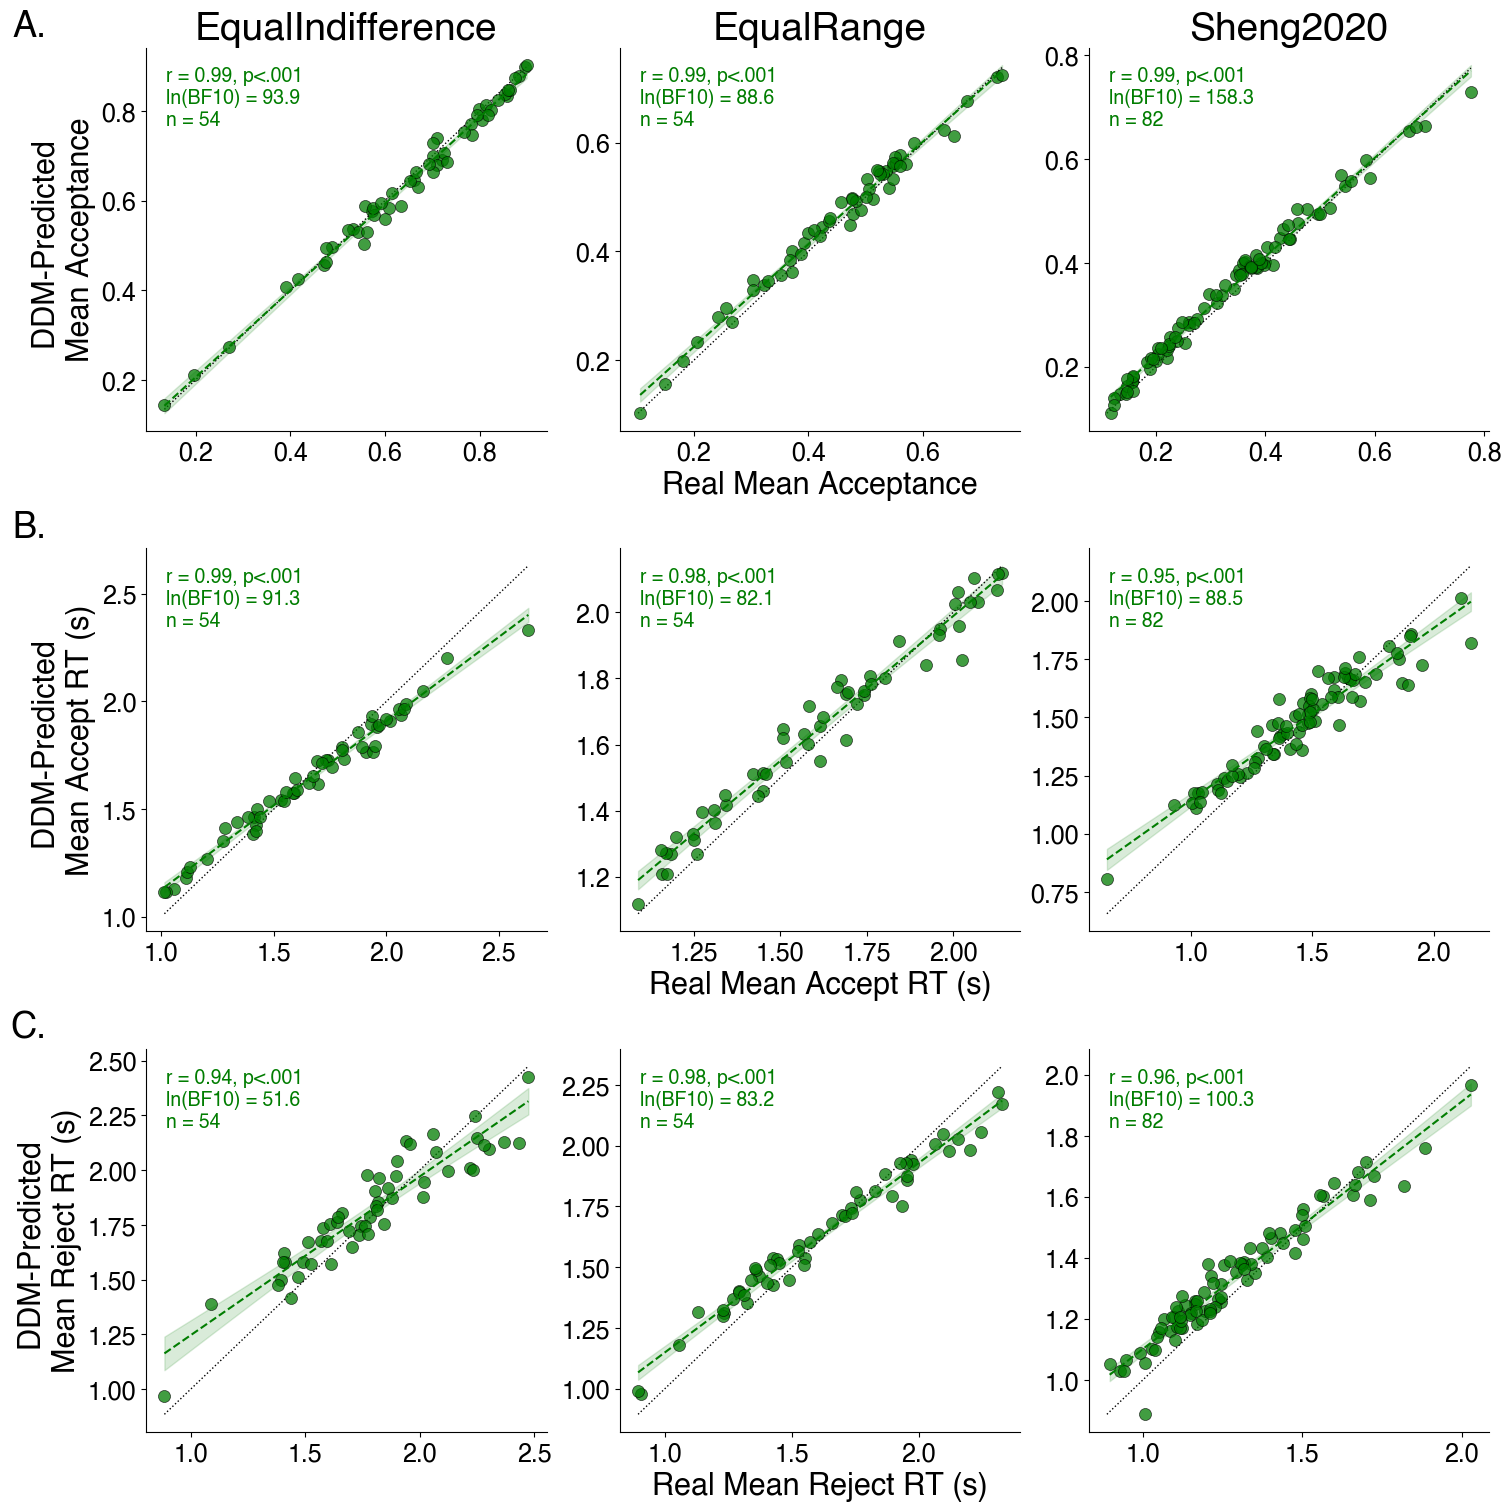

In [6]:
# (real_agg_col, sim_agg_col, accept_filter, row_label)
ROW_SPECS = [
    ("accept", "mean_accept", None, "Mean Acceptance"),
    ("rt",     "mean_rt",     1,    "Mean Accept RT (s)"),
    ("rt",     "mean_rt",     0,    "Mean Reject RT (s)"),
]

behavioral_data = load_behavioral_data()
sim_data = add_ddm_sim_choice_history(load_ddm_simulated(SIM_MODEL))

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15), layout="constrained")

for row, (real_agg_col, sim_agg_col, accept_filter, label) in enumerate(ROW_SPECS):
    for col, ds in enumerate(DATASETS):
        ax = axes[row, col]
        x, y = merge_subject_means(behavioral_data, sim_data, ds, real_agg_col, sim_agg_col, accept_filter)
        plot_spearman_corr(ax, x, y)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        if row == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds))
        if col == 0:
            ax.set_ylabel(f"DDM-Predicted \n{label}")
        if col == 1:
            ax.set_xlabel(f"Real {label}")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
row_labels = ["A.", "B.", "C."]
for row, row_label in enumerate(row_labels):
    axes[row, 0].text(-0.25, 1.1, row_label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figureS2.svg", dpi=300, bbox_inches="tight")
plt.show()